In [68]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# SVHN 이미지 다중분류 실습문제

실제 거리 사진에서 숫자 이미지를 입력받아 0부터 9까지 10개의 숫자 중 하나로 분류하는 CNN(합성곱 신경망)을 구현하시오.

- 데이터셋: SVHN (Street View House Numbers)
- 학습 데이터: 73,257개
- 테스트 데이터: 26,032개
- 추가 데이터: 531,131개 (이번 실습에서는 사용하지 않음)
- 이미지 크기: 32 × 32


| 구분 | 내용 |
|---|---|
| 데이터 | SVHN |
| 입력 데이터 | RGB 이미지 |
| 입력 Shape | `(3, 32, 32)` |
| 출력 데이터 | 10개 클래스 |
| 정답 레이블 | 0~9 |
| 손실함수 | `CrossEntropyLoss` |
| Optimizer | Adam |

#### STEP 1. 라이브러리 불러오기 및 실행 환경 확인

**실습 조건**

| 변수 | 값 |
|---|---:|
| `BATCH_SIZE` | 64 |
| `EPOCH` | 10 |
| `LR` | 0.001 |
| `IMAGE_SIZE` | 32 |

In [69]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import random_split, DataLoader
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [70]:
BATCH_SIZE=64
EPOCH=10
LR=1e-3
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN'
dataset = 'SVHN'
save_model_path = f'results/{model_type}_{dataset}.pt'

#### STEP 2. 데이터 다운로드 및 데이터셋 확인

**문제**

1. `torchvision.datasets.SVHN`을 이용하여 학습 데이터를 다운로드하시오.
2. 테스트 데이터를 다운로드하시오.
3. `split="train"`과 `split="test"`를 구분하여 사용하시오.
4. 학습 데이터와 테스트 데이터의 개수를 출력하시오.
5. 이미지와 정답 레이블의 구조를 확인하시오.

**주의** SVHN 데이터셋에서는 숫자 0의 레이블이 10으로 저장되어 있다. 모델에서 사용할 클래스 번호 0~9에 맞도록 변환하여 사용

In [71]:
transform = transforms.ToTensor()
train_DS = datasets.SVHN(root='data', split="train", download=True, transform=transform)
test_DS = datasets.SVHN(root='data', split="test", download=True, transform=transform)


In [72]:
print(len(train_DS))
print(len(test_DS))



73257
26032


#### STEP 3. 이미지 전처리 및 DataLoader 생성

**전처리 조건**

- `transforms.ToTensor()`를 적용한다.
- 이미지 크기는 32 × 32를 유지한다.
- 학습 데이터 중 20%를 검증 데이터로 분리한다.

**문제**

1. 이미지 전처리를 구성하시오.
2. 학습 데이터와 테스트 데이터에 전처리를 적용하시오.
3. SVHN의 정답 레이블 10을 0으로 변환하시오.
4. 시각화를 위해 classes를 문자열로 바꾸어 넣으시오.
5. 학습 데이터의 20%를 검증 데이터로 분리하시오.
6. 학습·검증·테스트용 `DataLoader`를 생성하시오.
7. 학습 데이터는 `shuffle=True`, 검증 및 테스트 데이터는 `shuffle=False`로 설정하시오.
8. 첫 번째 배치의 이미지와 정답 레이블 shape를 출력하시오.
9. 이미지 9장을 정답 레이블과 함께 시각화하시오.

**주의:** SVHN 데이터셋에는 `classes` 속성이 기본 제공되지 않는다. 숫자 클래스 이름 목록을 준비하여 시각화 및 혼동행렬에 활용하시오.

In [73]:
classes = [str(i) for i in range(10)]

print(classes)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=True)

total_size = len(train_DS)
train_size = int(total_size*0.8)

val_size = total_size - train_size

train_DS, val_DS = random_split(train_DS, [train_size, val_size])



['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


torch.Size([64, 3, 32, 32])
이미지 크기 : torch.Size([64, 3, 32, 32])
레이블 크기 : torch.Size([64])


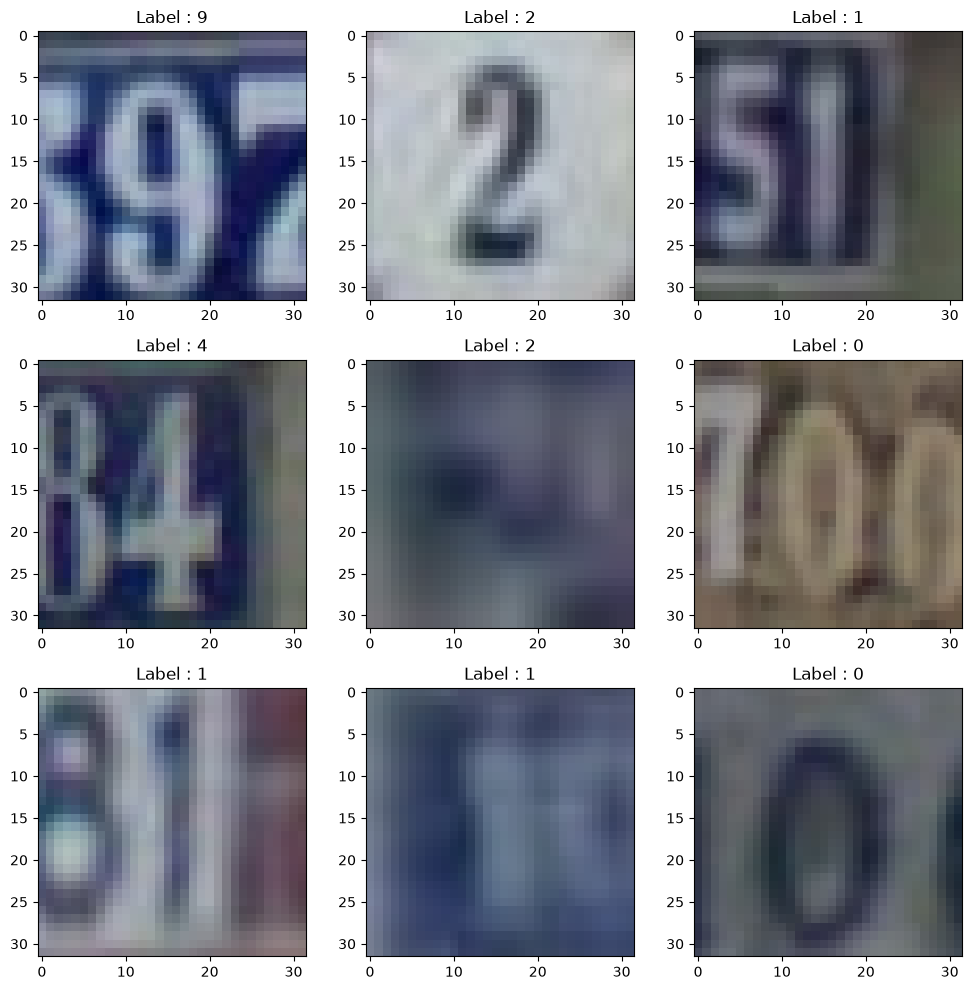

첫번쨰 정답 레이블 : 9


In [74]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

print('이미지 크기 :', x_batch.shape)
print('레이블 크기 :', y_batch.shape)

y_batch[y_batch == 10] = 0

plt.figure(figsize=(10,10))

for idx in range(9):
    plt.subplot(3,3,idx+1)
    plt.imshow(x_batch[idx].permute(1,2,0))
    plt.title(f'Label : {classes[y_batch[idx].item()]}')
    
plt.tight_layout()  
plt.show()

print('첫번쨰 정답 레이블 :', y_batch[0].item())

#### STEP 4. CNN 모델 만들기

**목표:** 이미지에서 숫자의 특징을 추출하는 CNN 모델을 구성한다.

**모델 조건**

- 입력: 3채널 RGB 이미지, 크기 32×32
- 첫 번째 합성곱 층: 3 → 32 채널, 커널 3×3, padding=1
- 두 번째 합성곱 층: 32 → 64 채널, 커널 3×3, padding=1
- 세 번째 합성곱 층: 64 → 128 채널, 커널 3×3, padding=1
- 각 합성곱 층 뒤에 ReLU와 2×2 MaxPool을 적용한다.
- `AdaptiveAvgPool2d((1, 1))`로 특징맵 크기를 1×1로 맞춘다.
- Flatten 후 완전연결층을 적용한다.
- 출력층: `Linear(128, 10)`

**문제**

1. `nn.Module`을 상속받아 CNN 클래스를 정의하시오.
2. `forward()` 함수를 구현하시오.
3. 모델을 생성하고 `DEVICE`로 이동하시오.
4. 모델 구조를 출력하시오.
5. 임의의 입력 5장으로 출력 shape를 확인하시오. 결과는 `(5, 10)`이어야 한다.

In [75]:
class CNN(nn.Module):                           # (3,32,32)
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),         # (32, 32,32)
                                    nn.BatchNorm2d(32),
                                    nn.ReLU()
                                    )
        self.Maxpool1 = nn.MaxPool2d(2)                                 # (32,16,16)
        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),        # (64,16,16)
                                            nn.BatchNorm2d(64),
                                            nn.ReLU()
                                            )
        self.Maxpool2 = nn.MaxPool2d(2)                                 # (64,8,8)
        self.conv3=nn.Sequential(nn.Conv2d(64,128,3,padding=1),         # (128, 8,8)
                                nn.BatchNorm2d(128),
                                nn.ReLU()
                                )
        self.Maxpool3 = nn.MaxPool2d(2)                                 # (128,4,4)

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.Maxpool1(x)
        x = self.conv2(x)
        x = self.Maxpool2(x)
        x = self.conv3(x)
        x = self.Maxpool3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x
        
        

In [76]:
model = globals()[model_type]().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_feat

#### STEP 5. 모델 학습시키기

**학습 조건**

- Loss function: `nn.CrossEntropyLoss()`
- Optimizer: `optim.Adam()`
- Learning Rate: `0.001`
- Epoch: 10
- Batch size: 64

**문제**

1. 손실함수를 정의하시오.
2. Optimizer를 정의하시오.
3. `multiclass_functions.py`의 `Train()` 함수를 이용하여 모델을 학습시키시오.
4. Epoch별 평균 Train Loss를 기록하시오.
5. 학습 Loss 그래프를 시각화하시오.

Epoch : 1, train loss : 1.468
------------------------------
Epoch : 2, train loss : 0.713
------------------------------
Epoch : 3, train loss : 0.511
------------------------------
Epoch : 4, train loss : 0.428
------------------------------
Epoch : 5, train loss : 0.379
------------------------------
Epoch : 6, train loss : 0.346
------------------------------
Epoch : 7, train loss : 0.317
------------------------------
Epoch : 8, train loss : 0.298
------------------------------
Epoch : 9, train loss : 0.278
------------------------------
Epoch : 10, train loss : 0.262
------------------------------


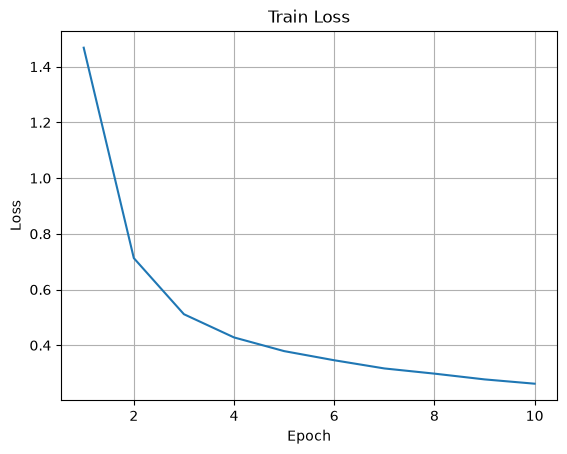

In [77]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr = LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train Loss')
    plt.grid()

#### STEP 6. 모델 저장 및 불러오기

**문제**

1. 학습이 끝난 모델의 `state_dict()`를 `results` 폴더에 저장하시오.
2. 동일한 CNN 구조를 새로 생성하시오.
3. 저장한 가중치를 `torch.load(..., map_location=DEVICE)`로 불러오시오.
4. 새 모델에 `load_state_dict()`를 적용하시오.
5. 불러온 모델을 `DEVICE`로 이동하고 `eval()` 모드로 전환하시오.

저장 파일명 예시: `CNN_SVHN.pt`

In [80]:
torch.save(model.state_dict(), "results/CNN_SVHN.pt")

new_model = CNN()

load_model = torch.load( "results/CNN_SYHN.pt", map_location = DEVICE, weights_only = False)

new_model.load_state_dict(load_model)

new_model = new_model.to(DEVICE)
new_model.eval()

CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_feat

#### STEP 7. 모델 테스트하기

**문제**

1. 불러온 모델을 이용하여 테스트 데이터의 예측값을 계산하시오.
2. `torch.no_grad()`를 이용하여 추론하시오.
3. `argmax(dim=1)`로 예측 클래스를 구하시오.
4. `multiclass_functions.py`의 `Test()` 함수를 이용하여 테스트 정확도를 계산하시오.
5. 정답 개수와 전체 테스트 데이터 개수를 출력하시오.

In [85]:
new_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = new_model(x_batch)
    pred = y_hat.argmax(dim=1)

    if model_type == 'CNN':
        feature_map1 = new_model.conv1(x_batch)
        feature_map2 = new_model.conv2(new_model.Maxpool1(feature_map1))
        feature_map3 = new_model.conv3(new_model.Maxpool2(feature_map2))

    elif model_type =='CNN_deep':
        feature_map1 = new_model.conv_block1(x_batch)
        feature_map2 = new_model.conv_block2(new_model.Maxpool1(feature_map1))
        feature_map3 = new_model.conv_block3(new_model.Maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()



#### STEP 8. 테스트 결과 시각화

**문제**

1. 테스트 이미지 6장을 시각화하시오.
2. 각 이미지의 실제 정답과 예측 결과를 표시하시오.
3. 정답과 예측이 다르면 제목을 빨간색으로 표시하시오.

**주의:** SVHN은 기본적으로 `classes` 속성을 제공하지 않으므로 숫자 클래스 이름 목록을 사용하시오.

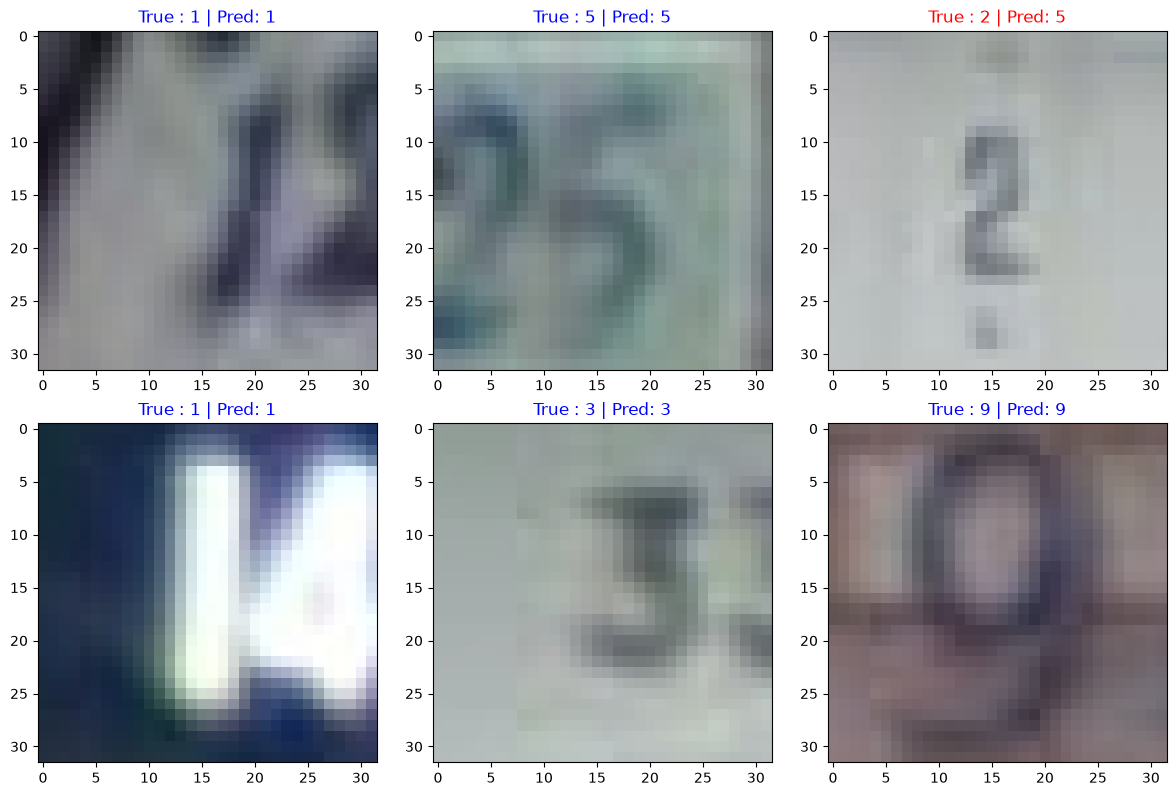

In [90]:
new_model.eval()

with torch.no_grad():
    output = new_model(x_batch)
    preds = output.argmax(dim=1).cpu()

class_names = [str(i) for i in range(10)]

fig, axes = plt.subplots(2,3, figsize = (12,8))

for i, ax in enumerate(axes.flat):
    img = x_batch[i].cpu().permute(1,2,0)
    true_label = int(y_batch[i])
    pred_label = int(preds[i])

    color = 'blue' if true_label == pred_label else 'r'

    ax.imshow(img)
    ax.set_title(
        f'True : {class_names[true_label]} | Pred: {class_names[pred_label]}',
        color = color
    )

plt.tight_layout()
plt.show()


#### STEP 9. 혼동행렬 및 오분류 이미지 분석

**문제 1. Confusion Matrix**

1. `plot_confusion_matrix()` 함수를 이용하여 혼동행렬을 시각화하시오.
2. 행(Row)은 실제 클래스, 열(Column)은 예측 클래스로 표시하시오.
3. 숫자별 정답 개수와 오분류 개수를 확인하시오.

**문제 2. 오분류 이미지 확인**

1. 테스트 데이터에서 실제 정답과 예측값이 다른 인덱스를 찾으시오.
2. 오분류 이미지 중 최대 9장을 시각화하시오.
3. 이미지 위에 실제 정답과 예측값을 표시하시오.
4. 오분류 이미지가 없으면 '오분류 이미지가 없습니다'를 출력하시오.

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9')])

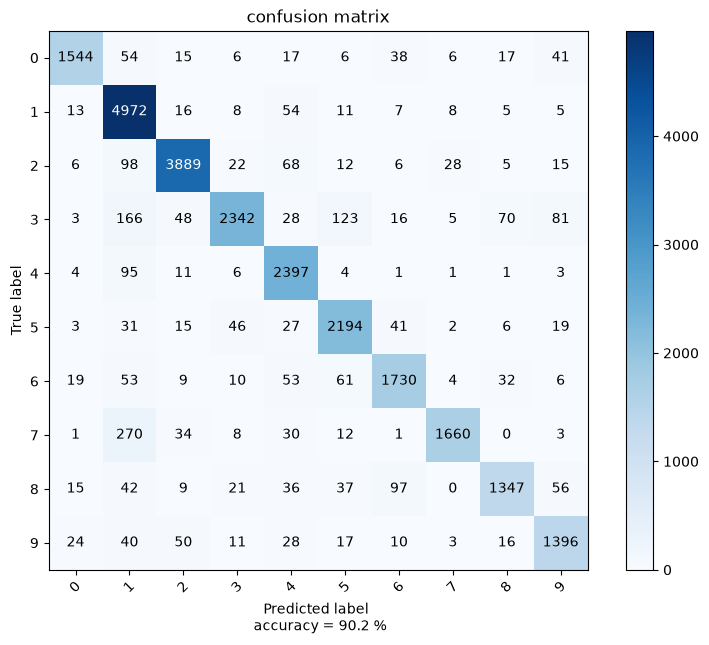

In [96]:
class_name = [str(i) for i in range(10)]
test_DL.dataset.classes = class_names
confusion = get_conf(new_model, test_DL)
plot_confusion_matrix(confusion, class_name)
plt.xticks(rotation=45)

#### STEP 10. 파라미터 개수 확인

**문제**

1. 학습 가능한 전체 파라미터 개수를 출력하시오.
2. Conv2d와 Linear 계층의 파라미터 개수를 각각 확인하시오.
3. CNN 모델의 학습 가능한 파라미터가 어느 계층에 많이 분포하는지 확인하시오.

In [ ]:
total_param = sum(p.numel() for p in model.parameters())